# Visualizing a PDS4 Digital Elevation Model

This notebook searches the PDS Registry for PDS4 raster products, loads a lunar
digital elevation model (DEM) and renders it inline with matplotlib and GDAL.

It deliberately avoids `pds4_tools.view()`: the PDS4 Viewer is a Tkinter
application and fails in headless environments (CI runners, remote servers,
Binder) with `ModuleNotFoundError: No module named '_tkinter'`. Everything below
runs with the non-interactive matplotlib backend.

## Step 0: Import Libraries

In [1]:
%matplotlib inline

import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pds4_tools
import requests

# Keep the inline figures light enough to be committed with the notebook.
plt.rcParams["figure.dpi"] = 72

## Step 1: Search for PDS4 raster products and load them with pds4_tools

Below demonstrates how the raster data was identified in PDS4 using 4 search parameters.
1. Identification Area: to limit search results to observational products
2. Harvest_Info: to look at products in the geo sciences node
3. Array_2d_Image: to identify image data products
4. Primary_Result_Summary: to identify processed data products

In [2]:
PDS_API = "https://pds.nasa.gov/api/search/1/products"

response = requests.get(PDS_API, params={
    "q": '((pds:Identification_Area.pds:product_class eq "Product_Observational") '
         'and (ops:Harvest_Info.ops:node_name eq "PDS_GEO") '
         'and (pds:Array_2D_Image.pds:axes eq "2") '
         'and (pds:Primary_Result_Summary.pds:processing_level eq "Derived"))',
    "limit": 3000,
})
response.raise_for_status()

resp_data = response.json()["data"]

xml_urls = []
for prod in resp_data:
    xml_urls.append([prod["properties"]["ops:Label_File_Info.ops:file_ref"][0]])

In [3]:
print(f"{len(xml_urls)} labels returned, showing the first five:")
display(xml_urls[:5])

3000 labels returned, showing the first five:


[['https://pds-geosciences.wustl.edu/msl/msl-m-chemcam-libs-4_5-rdr-v1/mslccm_1xxx/data/sol04480/cr0_795205827prc_f1140366ccam04479l1.xml'],
 ['https://pds-geosciences.wustl.edu/msl/msl-m-chemcam-libs-4_5-rdr-v1/mslccm_1xxx/data/sol04481/cr0_795296476prc_f1140534ccam01481l1.xml'],
 ['https://pds-geosciences.wustl.edu/msl/msl-m-chemcam-libs-4_5-rdr-v1/mslccm_1xxx/data/sol04481/cr0_795296616prc_f1140534ccam02481l1.xml'],
 ['https://pds-geosciences.wustl.edu/msl/msl-m-chemcam-libs-4_5-rdr-v1/mslccm_1xxx/data/sol04484/cr0_795562992prc_f1140780ccam02484l1.xml'],
 ['https://pds-geosciences.wustl.edu/msl/msl-m-chemcam-libs-4_5-rdr-v1/mslccm_1xxx/data/sol04485/cr0_795653957prc_f1140918ccam03484l1.xml']]

## Step 2: Resolve the products we want to visualize

The result list above is large and its order is not guaranteed, so indexing into
it (`xml_urls[1][0]`) does not reliably return the same product twice. We instead
look the two products up by logical identifier:

* a global lunar DEM from the LRO Mini-RF bistatic archive, and
* a Mini-RF S1 (total backscatter power) strip over the same body, as an example
  of a non-elevation map.

In [4]:
DEM_LID = "urn:nasa:pds:lro_minirf_bistatic:data_derived:mrf_sar_dem16"
MAP_LID = "urn:nasa:pds:lro_minirf_bistatic:data_derived:lxt_2023224125008_s1_19n055"


def find_label_url(lid):
    """Return the label URL of the single PDS4 product with this logical identifier."""
    response = requests.get(PDS_API, params={
        "q": f'(pds:Identification_Area.pds:logical_identifier eq "{lid}")',
        "limit": 1,
    })
    response.raise_for_status()
    hits = response.json()["data"]
    if not hits:
        raise LookupError(f"no product registered for {lid}")
    return hits[0]["properties"]["ops:Label_File_Info.ops:file_ref"][0]


dem_label_url = find_label_url(DEM_LID)
map_label_url = find_label_url(MAP_LID)

print(dem_label_url)
print(map_label_url)

https://pds-geosciences.wustl.edu/lro/urn-nasa-pds-lro_minirf_bistatic/data_derived/mrf_sar_dem16_v1.xml
https://pds-geosciences.wustl.edu/lro/urn-nasa-pds-lro_minirf_bistatic/data_derived/2023_224_1/lxt_2023224125008_s1_19n055_v1.xml


## Step 3: Read the DEM and plot it inline

`pds4_tools.read()` returns the structures described by the label and applies the
`scaling_factor` and `value_offset` from `Element_Array`, so the DEM array comes
back as a planetary radius in kilometres. Subtracting the body radius from the
`Geodetic_Model` turns it into an elevation in metres.

In [5]:
KM = 1000.0  # metres per kilometre


def label_value(label, path, unit_in_m=None):
    """Read a numeric element from a PDS4 label, converting km to m when asked."""
    element = label.find(path)
    value = float(element.text)
    if unit_in_m and element.attrib.get("unit", "").startswith("km"):
        value *= KM
    return value


dem_structures = pds4_tools.read(dem_label_url, quiet=True)
dem_label = dem_structures.label

body_radius_m = label_value(dem_label, ".//cart:a_axis_radius", unit_in_m=True)
radius_km = np.asarray(dem_structures[0].data, dtype="float32")
elevation_m = radius_km * KM - body_radius_m

print(f"shape {elevation_m.shape}, elevation {elevation_m.min():.0f} m to {elevation_m.max():.0f} m")

shape (2880, 5760), elevation -9048 m to 10688 m


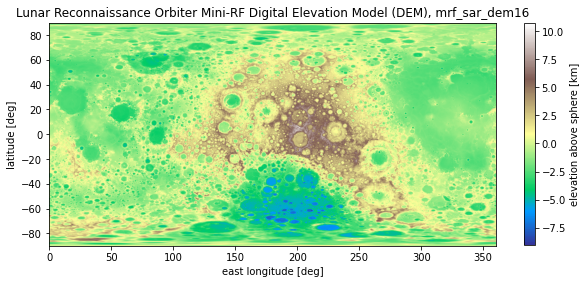

In [6]:
extent = [
    float(dem_label.findtext(".//cart:west_bounding_coordinate")),
    float(dem_label.findtext(".//cart:east_bounding_coordinate")),
    float(dem_label.findtext(".//cart:south_bounding_coordinate")),
    float(dem_label.findtext(".//cart:north_bounding_coordinate")),
]

fig, ax = plt.subplots(figsize=(10, 5))
image = ax.imshow(elevation_m / KM, cmap="terrain", extent=extent, origin="upper")
ax.set_title(dem_label.findtext(".//Identification_Area/title"))
ax.set_xlabel("east longitude [deg]")
ax.set_ylabel("latitude [deg]")
fig.colorbar(image, ax=ax, label="elevation above sphere [km]", shrink=0.8)
plt.show()

## Step 4: Read the backscatter map

Mini-RF strips mark gaps with a special constant, which has to be masked before
plotting. The backscatter dynamic range spans several decades, so the values are
shown on a decibel scale.

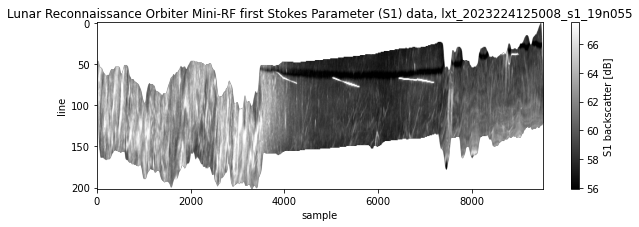

In [7]:
map_structures = pds4_tools.read(map_label_url, quiet=True)
map_label = map_structures.label

backscatter = np.asarray(map_structures[0].data, dtype="float32")

for constant in ("missing_constant", "not_applicable_constant", "invalid_constant"):
    element = map_label.find(f".//Special_Constants/{constant}")
    if element is not None:
        backscatter = np.where(backscatter == float(element.text), np.nan, backscatter)

with np.errstate(divide="ignore", invalid="ignore"):
    backscatter_db = 10.0 * np.log10(np.where(backscatter > 0, backscatter, np.nan))

low, high = np.nanpercentile(backscatter_db, [2, 98])

fig, ax = plt.subplots(figsize=(10, 3))
image = ax.imshow(backscatter_db, cmap="gray", vmin=low, vmax=high, aspect="auto")
ax.set_title(map_label.findtext(".//Identification_Area/title"))
ax.set_xlabel("sample")
ax.set_ylabel("line")
fig.colorbar(image, ax=ax, label="S1 backscatter [dB]")
plt.show()

## Step 5: GDAL DEM visualization: hillshade, colour relief and slope

GDAL's `DEMProcessing` is the standard way to turn an elevation grid into the
derived products a DEM is usually inspected with. The PDS4 array plus the
georeferencing in the `cart:` label elements is enough to write a GeoTIFF that
GDAL can process, including the lunar spheroid.

GDAL is optional here. When the `osgeo` bindings are not installed the notebook
computes the hillshade with NumPy instead, so the notebook still executes
end to end. To get the GDAL path, install the bindings matching your system
GDAL, for example `pip install gdal=="$(gdal-config --version)"`.

In [8]:
try:
    from osgeo import gdal, osr

    gdal.UseExceptions()
    HAVE_GDAL = True
except ImportError:
    HAVE_GDAL = False

print("GDAL available:", HAVE_GDAL)

GDAL available: True


In [9]:
def write_geotiff(path, elevation_m, label):
    """Write the DEM to a GeoTIFF using the cart: georeferencing from the label."""
    resolution_m = label_value(label, ".//cart:pixel_resolution_x", unit_in_m=True)
    upper_left_x = label_value(label, ".//cart:upperleft_corner_x", unit_in_m=True)
    upper_left_y = label_value(label, ".//cart:upperleft_corner_y", unit_in_m=True)
    radius_m = label_value(label, ".//cart:a_axis_radius", unit_in_m=True)
    central_meridian = float(label.findtext(".//cart:longitude_of_central_meridian"))

    rows, columns = elevation_m.shape
    dataset = gdal.GetDriverByName("GTiff").Create(
        path, columns, rows, 1, gdal.GDT_Float32
    )
    dataset.SetGeoTransform(
        (upper_left_x, resolution_m, 0.0, upper_left_y, 0.0, -resolution_m)
    )

    spatial_reference = osr.SpatialReference()
    spatial_reference.ImportFromProj4(
        f"+proj=eqc +R={radius_m:.1f} +lat_ts=0 +lon_0={central_meridian} +units=m +no_defs"
    )
    dataset.SetProjection(spatial_reference.ExportToWkt())

    dataset.GetRasterBand(1).WriteArray(elevation_m)
    dataset.FlushCache()
    return path


def numpy_hillshade(elevation_m, resolution_m, azimuth=315.0, altitude=45.0, z_factor=5.0):
    """Horn gradient hillshade, used when the GDAL bindings are unavailable."""
    dy, dx = np.gradient(elevation_m * z_factor, resolution_m)
    slope = np.arctan(np.hypot(dx, dy))
    aspect = np.arctan2(-dx, dy)
    zenith = np.radians(90.0 - altitude)
    light = np.radians(360.0 - azimuth + 90.0)
    shaded = np.cos(zenith) * np.cos(slope) + np.sin(zenith) * np.sin(slope) * np.cos(
        light - aspect
    )
    return np.clip(shaded, 0.0, 1.0) * 255.0


AZIMUTH = 315.0
ALTITUDE = 45.0
Z_FACTOR = 5.0  # vertical exaggeration, the DEM is 1.9 km/pixel

In [10]:
resolution_m = label_value(dem_label, ".//cart:pixel_resolution_x", unit_in_m=True)
low, high = np.percentile(elevation_m, [2, 98])

if HAVE_GDAL:
    workdir = tempfile.mkdtemp(prefix="pds4_dem_")
    dem_tif = write_geotiff(os.path.join(workdir, "dem.tif"), elevation_m, dem_label)

    hillshade = gdal.DEMProcessing(
        os.path.join(workdir, "hillshade.tif"), dem_tif, "hillshade",
        computeEdges=True, azimuth=AZIMUTH, altitude=ALTITUDE, zFactor=Z_FACTOR,
    ).ReadAsArray()

    slope = gdal.DEMProcessing(
        os.path.join(workdir, "slope.tif"), dem_tif, "slope", computeEdges=True
    ).ReadAsArray()

    ramp = os.path.join(workdir, "color_ramp.txt")
    colors = ["8 29 88", "34 94 168", "65 182 196", "199 233 180", "255 255 217"]
    with open(ramp, "w") as handle:
        for fraction, color in zip(np.linspace(0.0, 1.0, len(colors)), colors):
            handle.write(f"{low + fraction * (high - low)} {color}\n")

    color_relief = gdal.DEMProcessing(
        os.path.join(workdir, "color_relief.tif"), dem_tif, "color-relief",
        colorFilename=ramp,
    ).ReadAsArray()
    color_relief = np.moveaxis(color_relief, 0, -1) / 255.0
else:
    hillshade = numpy_hillshade(elevation_m, resolution_m, AZIMUTH, ALTITUDE, Z_FACTOR)
    dy, dx = np.gradient(elevation_m, resolution_m)
    slope = np.degrees(np.arctan(np.hypot(dx, dy)))
    color_relief = plt.get_cmap("YlGnBu_r")(
        np.clip((elevation_m - low) / (high - low), 0.0, 1.0)
    )[..., :3]

print(f"hillshade {hillshade.shape}, slope up to {np.nanmax(slope):.1f} deg")

hillshade (2880, 5760), slope up to 34.0 deg


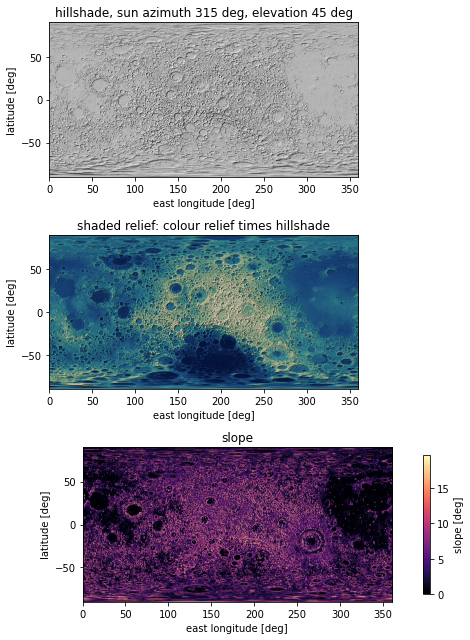

In [11]:
# Shaded relief: the GDAL colour relief modulated by the hillshade, the usual way
# a DEM is presented in a map product.
shaded_relief = np.clip(
    color_relief * (np.asarray(hillshade, dtype="float32") / 255.0)[..., None], 0.0, 1.0
)

fig, axes = plt.subplots(3, 1, figsize=(9, 9))

axes[0].imshow(hillshade, cmap="gray", extent=extent, origin="upper")
axes[0].set_title(f"hillshade, sun azimuth {AZIMUTH:.0f} deg, elevation {ALTITUDE:.0f} deg")

axes[1].imshow(shaded_relief, extent=extent, origin="upper")
axes[1].set_title("shaded relief: colour relief times hillshade")

slope_image = axes[2].imshow(
    slope, cmap="magma", extent=extent, origin="upper", vmax=np.nanpercentile(slope, 99)
)
axes[2].set_title("slope")
fig.colorbar(slope_image, ax=axes[2], label="slope [deg]", shrink=0.9)

for ax in axes:
    ax.set_xlabel("east longitude [deg]")
    ax.set_ylabel("latitude [deg]")

fig.tight_layout()
plt.show()